# 실사진 Pick+Place 인퍼런스

한 문장짜리 한국어 지시문(예: `"캔을 노란 바구니에 넣어줘"`)과 사진 경로만 바꿔가며 바로 결과를 확인하는 노트북.

1. 아래 **설정 / 모델 로드** 셀들을 한 번 실행한다 (모델 로딩에 시간이 좀 걸림, 이후엔 재실행 불필요).
2. 맨 아래 **여기만 고쳐서 실행** 셀의 `IMAGE_PATH`, `INSTRUCTION`만 바꿔가며 반복 실행하면 됨.

## 설정

In [1]:
import os

# 노트북이 notebooks/ 밑에 있으므로 리포 루트로 이동 (vatex 패키지 import에 필요)
REPO_ROOT = "/home/seongyeol/VATEX"
os.chdir(REPO_ROOT)

import sys
sys.path.append(".")

import numpy as np
import torch
import cv2
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

_nanum_path = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
if os.path.exists(_nanum_path):
    fm.fontManager.addfont(_nanum_path)
    plt.rcParams["font.family"] = "NanumGothic"
plt.rcParams["axes.unicode_minus"] = False

from detectron2.data import detection_utils as utils
from detectron2.data import transforms as T
from detectron2.config import get_cfg
from detectron2.checkpoint import DetectionCheckpointer
from detectron2.projects.deeplab import add_deeplab_config
from detectron2.modeling import build_model

import vatex  # noqa: registers datasets/model via package side effects
from vatex import add_vatex_config
from vatex.data.augmentation import build_augmentation
from vatex.utils.split_pnp_ko import split_pnp_instruction_ko

CONFIG = "configs/roborefit/swin/swin_base_ko_pnp.yaml"
WEIGHTS = "results/roborefit_pnp_finetune_ko/model_final.pth"

/home/seongyeol/VATEX/vatex/modeling/pixel_decoder/cmd.py:206: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  @autocast(enabled=False)
/root/anaconda3/envs/vatex/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/root/anaconda3/envs/vatex/lib/python3.9/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


## 모델 로드 (한 번만 실행)

In [2]:
cfg = get_cfg()
add_deeplab_config(cfg)
add_vatex_config(cfg)
cfg.merge_from_file(CONFIG)
cfg.MODEL.WEIGHTS = WEIGHTS
cfg.freeze()

model = build_model(cfg)
model.eval()
DetectionCheckpointer(model).load(cfg.MODEL.WEIGHTS)
augmentations = build_augmentation(cfg, is_train=False)
print("모델 로드 완료")

/root/anaconda3/envs/vatex/lib/python3.9/site-packages/torch/functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4314.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


모델 로드 완료


## 인퍼런스 함수

In [3]:
def build_input(file_name, expression):
    image = utils.read_image(file_name, format=cfg.INPUT.FORMAT)
    orig_h, orig_w = image.shape[:2]
    aug_input = T.AugInput(image)
    T.AugmentationList(augmentations)(aug_input)
    image = aug_input.image
    image_tensor = torch.as_tensor(np.ascontiguousarray(image.transpose(2, 0, 1)))
    return {
        "height": orig_h,
        "width": orig_w,
        "length": 1,
        "video_name": os.path.basename(file_name),
        "video_id": "0",
        "anno_id": 0,
        "exp_id": 0,
        "expression": expression,
        "image": [image_tensor],
        "instances": [],
        "file_names": [file_name],
    }


def run_one(file_name, expression):
    if expression is None:
        return None
    with torch.no_grad():
        out = model([build_input(file_name, expression)])
    pred_masks = out["pred_masks"]
    if len(pred_masks) == 0:
        return None
    return np.squeeze(pred_masks[0].numpy())


def run_pnp(image_path, instruction):
    """압축 문장 -> (pick, place) 자동 분리 -> 각각 추론 -> 나란히 시각화."""
    pick_expr, place_expr = split_pnp_instruction_ko(instruction)
    print(f'"{instruction}" -> pick="{pick_expr}"  place="{place_expr}"')

    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    pick_mask = run_one(image_path, pick_expr)
    place_mask = run_one(image_path, place_expr)

    fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
    axes[0].imshow(image)
    axes[0].set_title("원본 이미지")
    axes[0].axis("off")

    axes[1].imshow(image)
    if pick_mask is not None:
        ov = np.zeros((*pick_mask.shape, 4)); ov[pick_mask.astype(bool)] = [1, 0, 0, 0.5]; axes[1].imshow(ov)
    if place_mask is not None:
        ov = np.zeros((*place_mask.shape, 4)); ov[place_mask.astype(bool)] = [0, 1, 0, 0.5]; axes[1].imshow(ov)
    axes[1].set_title("모델 예측: 빨강=pick, 초록=place")
    axes[1].axis("off")

    fig.suptitle(f'지시문: "{instruction}"', fontsize=13)
    plt.tight_layout()
    plt.show()
    return pick_mask, place_mask

## 여기만 고쳐서 실행

"사이다를 노란색 바구니에 넣어줘" -> pick="사이다"  place="노란색 바구니"


/root/anaconda3/envs/vatex/lib/python3.9/site-packages/torch/_dynamo/eval_frame.py:838: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. In version 2.5 we will raise an exception if use_reentrant is not passed. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/root/anaconda3/envs/vatex/lib/python3.9/site-packages/torch/utils/checkpoint.py:86: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  warnings.warn(
/root/anaconda3/envs/vatex/lib/python3.9/site-packages/torch/_dynamo/eval_frame.py:838: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. In version 2.5 we will raise an exception if use_reentrant is not passed. use_reentrant=False is recommended, but if you need to preserve the curren

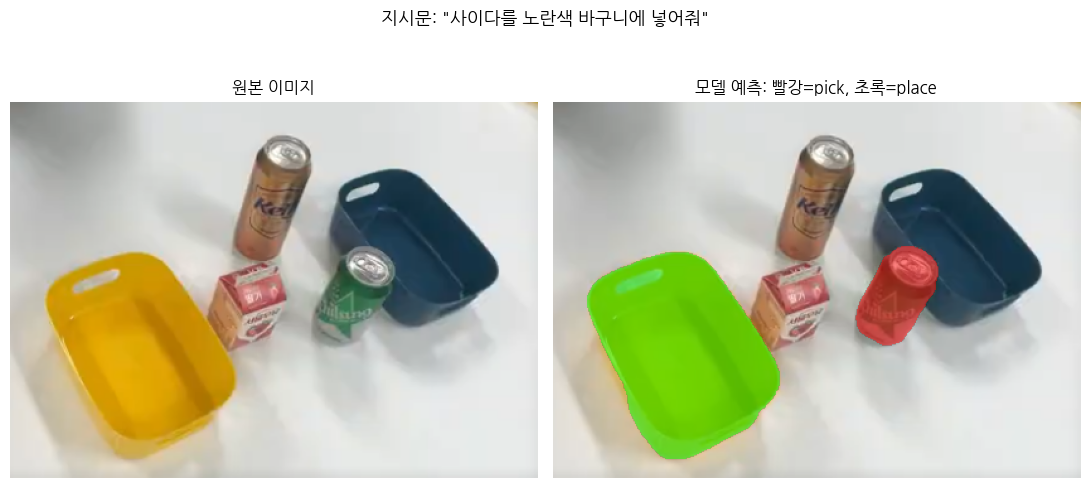

In [19]:
IMAGE_PATH = "/mnt/c/Users/SeongYeol/Pictures/testtt.png"
INSTRUCTION = "사이다를 노란색 바구니에 넣어줘"

_ = run_pnp(IMAGE_PATH, INSTRUCTION)